# 01 — Logistic Regression
### Telco Customer Churn Prediction

Logistic Regression is the simplest and most interpretable candidate. It sets the standard that the more complex models have to beat.

**Shared protocol** (identical in notebooks 01–06):
- Same training set (3,944 customers) and same 5 stratified folds (`random_state = 34`).
- Same preprocessing (`FINAL_PREP_CONFIG` from notebook 00): binary add-ons, one-hot `InternetService` and `Contract`, binary `Dependents`/`PaperlessBilling`, standardised `log(1 + tenure)` and `MonthlyCharges`.
- Same tuning procedure: **nested cross-validation** (inner 5-fold grid search, outer 5-fold evaluation), scored by PR-AUC.
- Unweighted classes; class imbalance is handled at the decision threshold (notebook 08) and examined in notebook 07.
- The test set is **not used**. The nested out-of-fold predictions saved at the end are used for comparison and threshold selection in notebook 08.

## 1. How the Algorithm Works

Logistic Regression models the **log-odds** of churn as a linear combination of the encoded features:

$$\log\frac{P(\text{churn})}{1-P(\text{churn})} = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p, \qquad P(\text{churn}) = \sigma(z) = \frac{1}{1+e^{-z}}$$

The **sigmoid** $\sigma$ maps the linear score $z$ to a probability between 0 and 1. The coefficients minimise the **log-loss** (cross-entropy) plus a regularisation penalty that shrinks them to reduce overfitting:
- `C` is the inverse penalty strength (smaller `C` = stronger shrinkage);
- `l1_ratio` selects an L2 penalty (0, shrinks all coefficients) or an L1 penalty (1, can set coefficients exactly to zero, an embedded form of feature selection).

$e^{\beta_j}$ is an **odds ratio**: the multiplicative change in the odds of churn for a one-unit change in $x_j$, holding the other features fixed.

## 2. Relevance, Assumptions and Limitations

- **Relevance:** the target is binary and the CS team needs explanations. Coefficients give each factor a direction and a size, and the model outputs probabilities that can feed a cost-based decision.
- **Assumptions:**
  - effects are **additive and monotonic on the log-odds scale**, so interactions must be supplied as features;
  - observations are independent;
  - no perfect multicollinearity (removed by the binary add-on encoding in notebook 00, Section 8.4).
- **Limitations:**
  - non-linear effects need transformations; this is why tenure enters as $\log(1+\text{tenure})$;
  - remaining collinearity (`MonthlyCharges` VIF ≈ 11) makes individual coefficients less stable than their joint effect.

## 3. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's shared src/ package importable, wherever Jupyter was started
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data_preprocessing.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import PartialDependenceDisplay
from src.data_preprocessing import FINAL_PREP_CONFIG, RANDOM_STATE, build_pipeline, load_raw_data, split_train_test
from src.evaluation import (cv_scores, final_search, fold_metrics, mean_std_table, nested_summary_row, run_nested_cv,
                            save_results, summarise_cv)
from src.visualization import plot_confusion, plot_permutation_importance, plot_reliability, save_figure, set_style

set_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

df = load_raw_data()                                       # validated raw data (read-only)
X_train, X_test, y_train, y_test = split_train_test(df)   # the project's single stratified 80/20 split
del X_test, y_test                                        # the test set is not used in this notebook
print(f"Training set: {X_train.shape[0]:,} customers, {int(y_train.sum()):,} churners ({y_train.mean():.2%})")
print("Preprocessing configuration (from notebook 00):", FINAL_PREP_CONFIG)

Training set: 3,944 customers, 1,053 churners (26.70%)
Preprocessing configuration (from notebook 00): {'contract': 'onehot', 'addons': 'binary', 'tenure': 'log'}


In [2]:
MODEL_NAME = "Logistic Regression"
SLUG = "01_logistic_regression"
INTERPRETABILITY_RANK = 1  # 1 = most interpretable

## 4. Preprocessing Pipeline

All encoded features are used. **Standardisation matters for this model.** The penalty acts on coefficient size, which depends on feature scale, so `tenure_log` and `MonthlyCharges` are scaled to mean 0 and SD 1 inside the pipeline. Dropping a reference category for every one-hot variable keeps the design matrix free of perfect collinearity with the intercept.

In [3]:
ESTIMATOR = LogisticRegression(solver="saga", max_iter=5000, random_state=RANDOM_STATE)


pipeline = build_pipeline(ESTIMATOR, **FINAL_PREP_CONFIG)
print("Pipeline steps:", [name for name, _ in pipeline.steps])
print("Transformers:", [(name, cols) for name, _, cols in pipeline.named_steps["preprocess"].transformers])
print("Model:", ESTIMATOR)

Pipeline steps: ['preprocess', 'model']
Transformers: [('binary', ['Dependents', 'PaperlessBilling']), ('addons', ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']), ('internet', ['InternetService']), ('contract', ['Contract']), ('tenure_log', ['tenure']), ('numeric', ['MonthlyCharges'])]
Model: LogisticRegression(max_iter=5000, random_state=34, solver='saga')


## 5. Baseline Configuration

The baseline uses scikit-learn's defaults (`C = 1`, L2 penalty, `lbfgs` solver) with the same pipeline and folds.

In [4]:
BASELINE_ESTIMATOR = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)


baseline_raw = cv_scores(build_pipeline(BASELINE_ESTIMATOR, **FINAL_PREP_CONFIG), X_train, y_train)
baseline = summarise_cv(baseline_raw)
display(mean_std_table(pd.DataFrame([baseline], index=["Baseline (5-fold CV, threshold 0.5)"])))
gap = {m: baseline[f"{m} train"] - baseline[f"{m} mean"] for m in ["F1", "ROC-AUC", "PR-AUC"]}
print("Train - validation gap:", {k: round(v, 3) for k, v in gap.items()})

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
"Baseline (5-fold CV, threshold 0.5)",0.797 ± 0.003,0.653 ± 0.024,0.521 ± 0.042,0.578 ± 0.016,0.847 ± 0.015,0.666 ± 0.027


Train - validation gap: {'F1': np.float64(0.012), 'ROC-AUC': np.float64(0.003), 'PR-AUC': np.float64(0.002)}


**Interpretation.**
- With default settings (`C = 1`), Logistic Regression reaches **PR-AUC 0.666 ± 0.027** and **ROC-AUC 0.847 ± 0.015**, far above the no-skill PR-AUC of 0.267.
- The gap between training-fold and validation-fold scores is tiny (PR-AUC +0.002), so the model is **not overfitting**: with 12 features and about 3,150 rows per fold, there is little room for it to memorise.
- At the reference threshold of 0.5, recall is only 0.521: about half of the churners would be missed. This is a threshold issue, addressed in notebook 08, not a ranking issue.

## 6. Hyperparameter Tuning Methodology


Hyperparameters are tuned with **nested cross-validation**:
- the 5 outer folds hold out 20% of the training set in turn;
- on the other 80%, a full grid search with its own inner 5-fold CV chooses the configuration;
- the chosen configuration, refitted on that 80%, predicts the held-out outer fold.

The outer-fold labels never influence tuning, so the resulting out-of-fold (OOF) probabilities are honest estimates of how the *whole hyperparameter-tuning procedure* performs on unseen customers. (The preprocessing configuration was fixed beforehand in notebook 00 using the same training folds; notebook 08, Section 6 shows that re-selecting it inside the nested loop changes the estimate only marginally.) A simpler "tune on everything, then cross-validate" design would reuse the same labels for selection and evaluation, which makes the estimates optimistic.

| Hyperparameter | Values | Role |
|---|---|---|
| `C` | 0.001, 0.01, 0.1, 1, 10 | Inverse regularisation strength, from very strong to weak (log scale) |
| `l1_ratio` | 0 (L2), 1 (L1) | Shrink all coefficients vs allow exact zeros; the `saga` solver supports both |

In [5]:
PARAM_GRID = {"model__C": [0.001, 0.01, 0.1, 1, 10], "model__l1_ratio": [0.0, 1.0]}


n_configurations = int(np.prod([len(v) for v in PARAM_GRID.values()]))
print(f"{n_configurations} configurations x 5 inner folds x 5 outer folds = {n_configurations * 25} fits "
      f"(+ {5} refits) in the nested CV")

10 configurations x 5 inner folds x 5 outer folds = 250 fits (+ 5 refits) in the nested CV


## 7. Nested Cross-Validation Results

In [6]:
nested = run_nested_cv(ESTIMATOR, PARAM_GRID, X_train, y_train, FINAL_PREP_CONFIG, compute_importance=True)
print(f"Nested CV wall time: {nested['seconds']:.1f} s\n")
display(nested["folds"].round(4))
print("Mean ± std over the 5 outer folds (accuracy, precision, recall and F1 at the reference threshold 0.5):")
display(pd.DataFrame([nested_summary_row(nested)], index=[MODEL_NAME]))
print("Hyperparameters chosen by the inner search in each outer fold:")
for fold, params in enumerate(nested["params"], start=1):
    print(f"  fold {fold}: {params}")

Nested CV wall time: 4.0 s



,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,log_loss
fold,,,,,,,,
1,0.7947,0.6256,0.5782,0.6010,0.8432,0.6454,0.1396,0.4197
2,0.8048,0.7080,0.4597,0.5575,0.8715,0.7191,0.1264,0.3919
3,0.7934,0.6263,0.5640,0.5935,0.8251,0.6610,0.1427,0.4453
4,0.7972,0.6667,0.4762,0.5556,0.8441,0.6597,0.1357,0.4183
5,0.8033,0.6950,0.4667,0.5584,0.8465,0.6454,0.1365,0.4178


Mean ± std over the 5 outer folds (accuracy, precision, recall and F1 at the reference threshold 0.5):


,PR-AUC,ROC-AUC,Brier score,Accuracy,Precision,Recall,F1
Logistic Regression,0.666 ± 0.027,0.846 ± 0.015,0.136 ± 0.005,0.799 ± 0.005,0.664 ± 0.034,0.509 ± 0.051,0.573 ± 0.020


Hyperparameters chosen by the inner search in each outer fold:
  fold 1: {'C': 1, 'l1_ratio': 1.0}
  fold 2: {'C': 0.1, 'l1_ratio': 0.0}
  fold 3: {'C': 10, 'l1_ratio': 0.0}
  fold 4: {'C': 0.1, 'l1_ratio': 0.0}
  fold 5: {'C': 0.1, 'l1_ratio': 0.0}


**Interpretation.**
- Nested CV gives **PR-AUC 0.666 ± 0.027** and **ROC-AUC 0.846 ± 0.015**, practically identical to the untuned baseline. Tuning brings no gain for this model.
- The inner search chooses different settings in different folds (`C` from 0.1 to 10, once an L1 penalty). Yet the outer scores barely change, which shows a **flat performance surface**: with few features and many rows, regularisation strength hardly matters.
- **Fold 2 is clearly easier** (PR-AUC 0.719) than the others (0.645–0.661). The spread across folds is larger than any difference between configurations.
- Brier score 0.136 ± 0.005.

## 8. Final Hyperparameters

The same grid search is run once on the full training set. Its refitted pipeline is this algorithm's final candidate, which notebook 09 evaluates if it is selected. Comparing the best search score with the nested estimate shows the optimism of a non-nested search.

In [7]:
search = final_search(ESTIMATOR, PARAM_GRID, X_train, y_train, FINAL_PREP_CONFIG)
final_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
final_summary = pd.Series({
    "best hyperparameters": final_params,
    "search CV PR-AUC (best of grid)": round(search.best_score_, 4),
    "nested CV PR-AUC": round(nested["folds"]["pr_auc"].mean(), 4),
    "optimism of the search score": round(search.best_score_ - nested["folds"]["pr_auc"].mean(), 4),
    "train-fold PR-AUC of best configuration": round(search.cv_results_["mean_train_score"][search.best_index_], 4),
})
display(final_summary.to_frame("value"))

,value
best hyperparameters,"{'C': 1, 'l1_ratio': 0.0}"
search CV PR-AUC (best of grid),0.6664
nested CV PR-AUC,0.6661
optimism of the search score,0.0002
train-fold PR-AUC of best configuration,0.6683


## 9. Diagnostics (Nested Out-of-Fold Predictions)

The confusion matrix uses the reference threshold of 0.5 only; the operating threshold is chosen in notebook 08. The reliability diagram checks whether predicted probabilities match observed churn rates (**calibration**), and the precision-recall curve shows the ranking quality across all thresholds (**discrimination**).

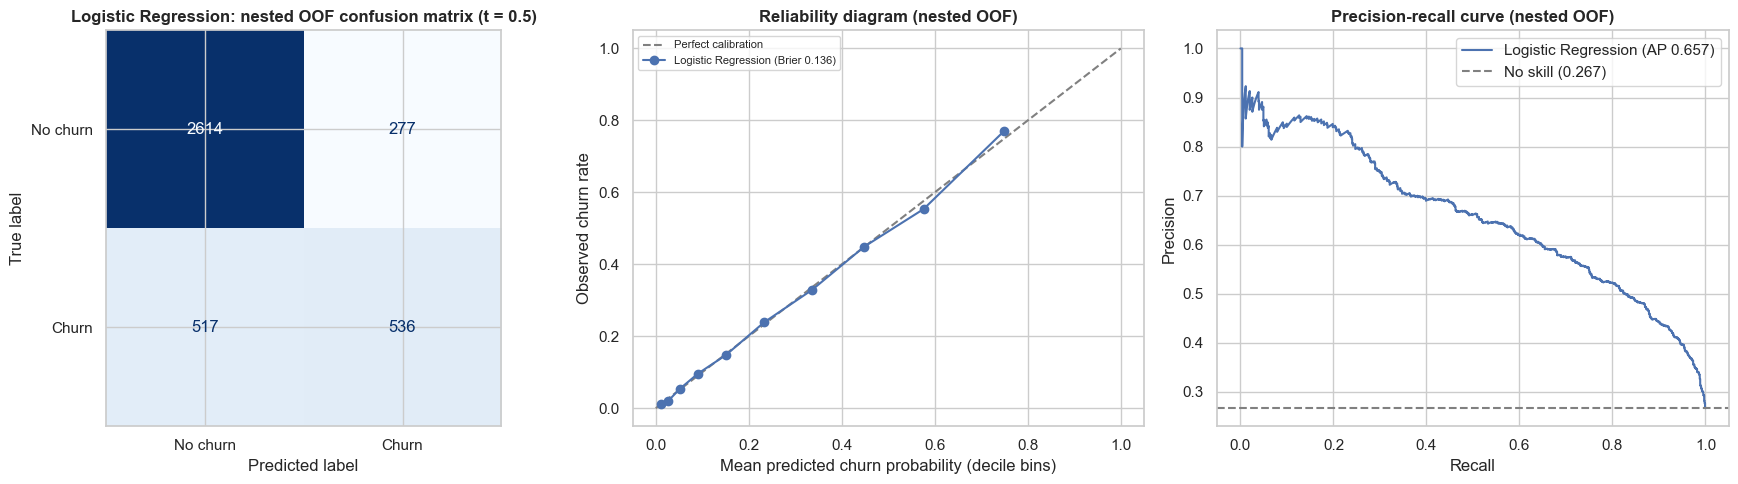

In [8]:
oof = nested["oof"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_confusion(axes[0], y_train, (oof >= 0.5).astype(int), f"{MODEL_NAME}: nested OOF confusion matrix (t = 0.5)")
plot_reliability(axes[1], y_train, {MODEL_NAME: oof}, "Reliability diagram (nested OOF)")
prec, rec, _ = precision_recall_curve(y_train, oof)
axes[2].plot(rec, prec, label=f"{MODEL_NAME} (AP {average_precision_score(y_train, oof):.3f})")
axes[2].axhline(y_train.mean(), linestyle="--", color="gray", label=f"No skill ({y_train.mean():.3f})")
axes[2].set_title("Precision-recall curve (nested OOF)")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
plt.tight_layout()
save_figure(fig, f"{SLUG}_diagnostics")
plt.show()

**Interpretation.**
- **Confusion matrix (t = 0.5):** of 1,053 training churners, 536 are caught and 517 missed, while 277 non-churners are flagged. This is the conservative behaviour of a 0.5 threshold when only 27% of customers churn.
- **Reliability diagram:** follows the diagonal across the full range, so the unweighted model is **well calibrated**. A predicted 30% means roughly 30% of such customers churn. Notebook 08 relies on this when converting probabilities into expected costs.
- **Precision-recall curve:** precision stays near 0.8 for the highest-risk 10–20% of churners and declines gradually. There is no single point where both precision and recall are high.

## 10. Model Interpretation

The final pipeline (fitted on the full training set in Section 8) is explained in three ways:
- **coefficients and odds ratios**: numerical features are standardised, so a coefficient is per standard deviation; categorical coefficients are relative to the reference categories `Dependents = No`, `PaperlessBilling = No`, add-on not subscribed, `InternetService = DSL`, `Contract = Month-to-month`;
- **partial-dependence plots**: the average predicted probability as one feature varies;
- **permutation importance** from the nested CV.

**Permutation importance** is the drop in PR-AUC when one original feature's values are shuffled. It is computed inside the nested CV, on each outer validation fold, for the model tuned and fitted without that fold, so it inherits no selection leakage. Shuffling one of two features that share information understates both. Importance describes what the *model* relies on; it is not a causal effect.

Intercept: -0.801


,coefficient,odds ratio
Contract_Two year,-1.799,0.166
Contract_One year,-0.900,0.407
tenure_log,-0.718,0.488
InternetService_No,-0.695,0.499
OnlineSecurity,-0.437,0.646
TechSupport,-0.347,0.707
Dependents_Yes,-0.309,0.734
OnlineBackup,-0.280,0.756
DeviceProtection,-0.007,0.993
InternetService_Fiber optic,0.300,1.350


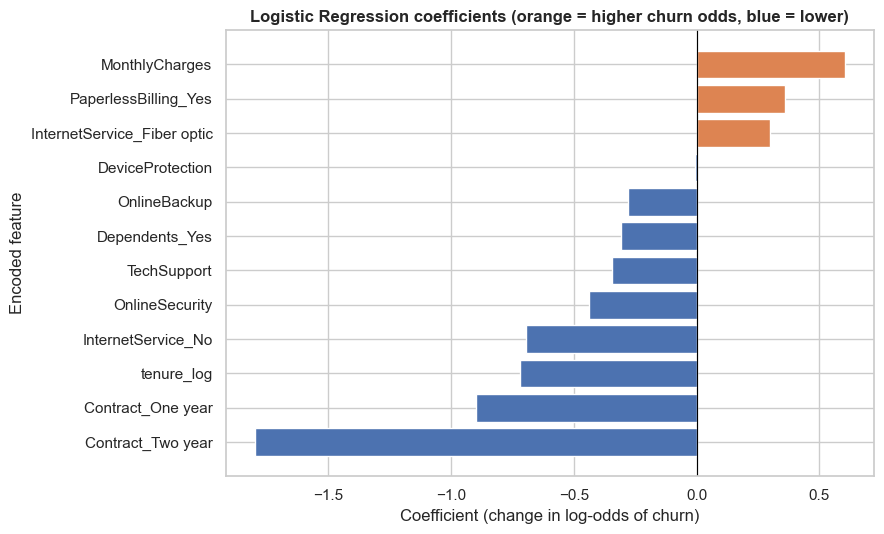

In [9]:
final_pipeline = search.best_estimator_
model = final_pipeline.named_steps["model"]
encoded_names = final_pipeline.named_steps["preprocess"].get_feature_names_out()
coef_table = pd.DataFrame({"coefficient": model.coef_[0], "odds ratio": np.exp(model.coef_[0])},
                          index=encoded_names).sort_values("coefficient")
print(f"Intercept: {model.intercept_[0]:.3f}")
display(coef_table.round(3))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(coef_table.index, coef_table["coefficient"],
        color=["#DD8452" if v > 0 else "#4C72B0" for v in coef_table["coefficient"]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Logistic Regression coefficients (orange = higher churn odds, blue = lower)")
ax.set_xlabel("Coefficient (change in log-odds of churn)")
ax.set_ylabel("Encoded feature")
plt.tight_layout()
save_figure(fig, f"{SLUG}_coefficients")
plt.show()

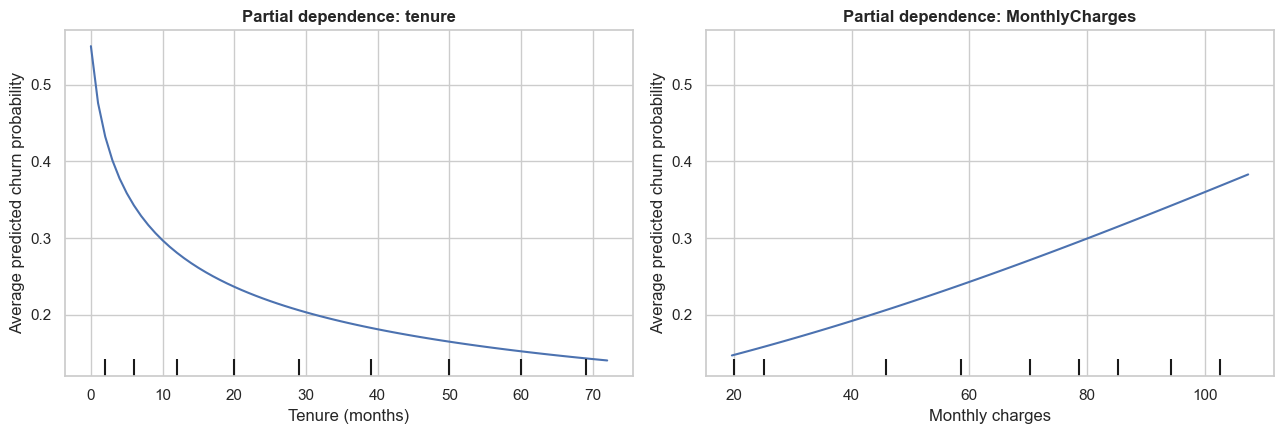

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
X_train_pdp = X_train.astype({"tenure": "float64"})  # partial dependence requires float inputs
PartialDependenceDisplay.from_estimator(final_pipeline, X_train_pdp, ["tenure", "MonthlyCharges"], kind="average",
                                        response_method="predict_proba", ax=axes)
axes[0].set_title("Partial dependence: tenure")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Average predicted churn probability")
axes[1].set_title("Partial dependence: MonthlyCharges")
axes[1].set_xlabel("Monthly charges")
axes[1].set_ylabel("Average predicted churn probability")
plt.tight_layout()
save_figure(fig, f"{SLUG}_partial_dependence")
plt.show()

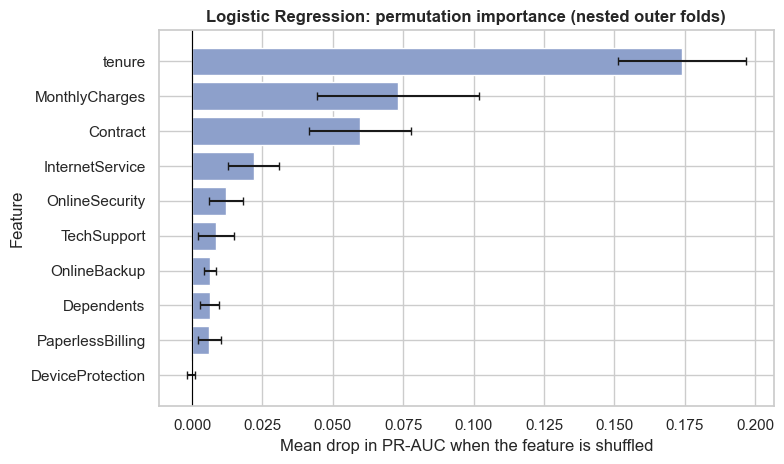

,mean,std
feature,,
tenure,0.1741,0.0227
MonthlyCharges,0.0730,0.0287
Contract,0.0597,0.0182
InternetService,0.0219,0.0090
OnlineSecurity,0.0120,0.0060
TechSupport,0.0084,0.0063
OnlineBackup,0.0064,0.0022
Dependents,0.0062,0.0033
PaperlessBilling,0.0062,0.0039


In [11]:
fig, ax = plt.subplots(figsize=(8, 4.8))
perm_summary = plot_permutation_importance(ax, nested["importance"],
                                           f"{MODEL_NAME}: permutation importance (nested outer folds)")
plt.tight_layout()
save_figure(fig, f"{SLUG}_permutation_importance")
plt.show()
display(perm_summary.sort_values("mean", ascending=False).round(4))

**Interpretation** (associations holding the other features constant; not causal effects)

**Associated with lower churn odds**
- **Contract:** two-year **OR 0.17** and one-year **OR 0.41** vs month-to-month. These are the strongest effects, and they remain large with tenure in the model, so commitment carries information beyond the length of the relationship.
- **Tenure:** OR 0.49 per SD of $\log(1+\text{tenure})$. The partial-dependence plot shows the average predicted probability falling from about **0.55 for brand-new customers** to about **0.30 after 10 months**, **0.20 after about 30 months** and **0.14 at 72 months**. That steep early drop is what the log transformation captures.
- **No internet service:** OR 0.50 vs DSL.
- **Add-ons:** OnlineSecurity (OR 0.65), TechSupport (0.71), OnlineBackup (0.76). **DeviceProtection has essentially no effect** (OR 0.99, permutation importance ≈ 0).
- **Dependents:** OR 0.73.

**Associated with higher churn odds**
- **MonthlyCharges:** OR 1.83 per SD (about 29.9 currency units), *at a fixed service mix*. The partial dependence rises from about 0.15 to 0.38 across the price range.
- **PaperlessBilling:** OR 1.44.
- **Fiber optic:** OR 1.35 vs DSL.

**Permutation importance:** `tenure` (0.174), `MonthlyCharges` (0.073) and `Contract` (0.060) dominate. `DeviceProtection` contributes nothing.

**Caveats**
- `MonthlyCharges` is collinear with the service features (VIF 11.2), so its coefficient and the internet-service coefficients share information.
- Odds ratios act on odds, not probabilities.
- Customers choose their contracts, so the contract effect may partly reflect *who* chooses long contracts rather than what the contract does.

## 11. Strengths, Weaknesses and Conclusion

**Strengths**
- Strong and stable ranking (nested PR-AUC 0.666, ROC-AUC 0.846) with no overfitting.
- Well-calibrated probabilities without any correction.
- Every prediction can be explained through 12 coefficients.
- Fast, with a tiny deployment footprint.

**Weaknesses**
- Assumes additive effects on the log-odds scale; interactions such as month-to-month × fiber are only approximated.
- Collinearity blurs the separate roles of price and service type.

**Conclusion:** Logistic Regression sets a demanding benchmark. Notebooks 02–06 test whether non-linear models can beat it by a meaningful margin.

### Saving the training-stage results

The nested OOF predictions, fold metrics, permutation importances and the final (training-set) pipeline are stored in `reports/cv_results/` for the comparison in notebook 08.

In [12]:
payload = {
    "name": MODEL_NAME, "slug": SLUG, "oof": nested["oof"], "folds": nested["folds"], "params": nested["params"],
    "importance": nested["importance"], "seconds": nested["seconds"], "baseline": baseline,
    "final_params": final_params, "final_search_score": search.best_score_,
    "final_train_score": search.cv_results_["mean_train_score"][search.best_index_],
    "final_pipeline": search.best_estimator_, "grid": PARAM_GRID, "prep_config": FINAL_PREP_CONFIG,
    "y_index": y_train.index.to_numpy(), "interpretability_rank": INTERPRETABILITY_RANK,
}
print("Saved:", save_results(SLUG, payload).relative_to(PROJECT_ROOT))

Saved: reports\cv_results\01_logistic_regression.joblib
